# 20. Series with exogenous variables

**Goal and requirements.** Use covariates in forecasting without leakage: declare what is known in advance (`future`) and what is only observed with the series (`past`), choose the variables automatically, let the selection decide whether they enter and compare with × without covariates through statistical tests. Examples: sales with a leading indicator (`bjsales`), electricity demand with temperature (`elecdaily`) and a study on four benchmarks. `stats` and `plot` extras; downloads the data on the first run.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.datasets import list_exog_datasets, load_exog_dataset

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Data and protocol

The datasets with covariates come from Rdatasets, with their `future` columns already marked. Every experiment uses the same bases (persistence, seasonal persistence, linear regression on lags and ARIMA, which becomes ARIMAX with covariates), the linear corrector, the `small` budget and seed 42.

In [2]:
SETTINGS = {
    "budget": "small",
    "base_models": ["naive", "seasonal_naive", "linear", "arima"],
    "correctors": ["linear"],
    "session_id": 42,
}
list_exog_datasets()

,description,frequency,future,source
name,,,,
seatbelts,"motoristas mortos ou feridos no Reino Unido, 1...",MS,[lei_cinto],datasets/Seatbelts
bjsales,vendas com indicador antecedente (Box–Jenkins)...,D,[],datasets/BJsales
uschange,"variação do consumo nos EUA ~ renda, produção,...",QS,[],fpp2/uschange
insurance,cotações de seguro ~ gasto planejado com publi...,MS,[publicidade_tv],fpp2/insurance
elecdaily,demanda elétrica diária de Victoria (Austrália...,D,[dia_util],fpp2/elecdaily
vic_elec_daily,demanda elétrica diária de Victoria em GWh ~ t...,D,"[feriado, fim_de_semana]",tsibbledata/vic_elec


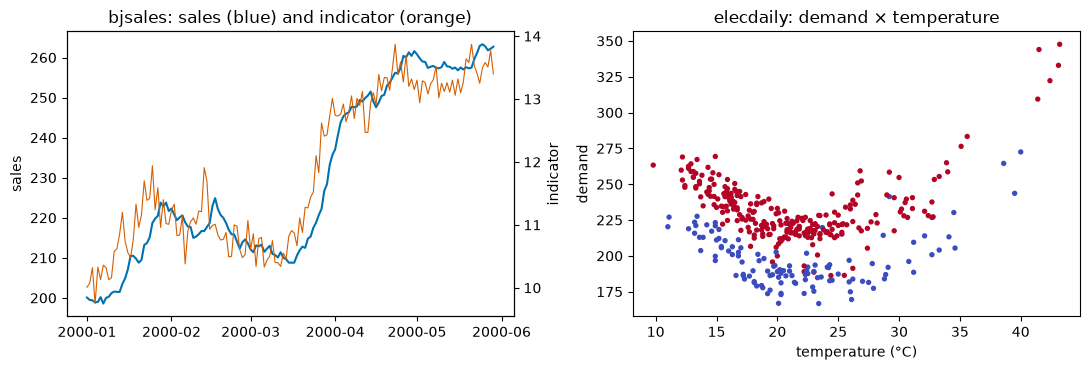

In [3]:
sales, indicator = load_exog_dataset("bjsales")
demand, weather = load_exog_dataset("elecdaily")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(sales.index, sales.to_numpy(), color="#0072B2", label="sales")
twin = axes[0].twinx()
twin.plot(indicator.index, indicator["indicador"].to_numpy(), color="#D55E00", linewidth=0.8)
axes[0].set(title="bjsales: sales (blue) and indicator (orange)", ylabel="sales")
twin.set_ylabel("indicator")
axes[1].scatter(weather["temperatura"], demand, s=8, c=weather["dia_util"], cmap="coolwarm")
axes[1].set(title="elecdaily: demand × temperature", xlabel="temperature (°C)", ylabel="demand")
fig.tight_layout()
plt.show()

## 2. Causal exploration

The `bjsales` indicator leads sales. With a 3-step horizon it is `past`: it enters lagged by at least 3. `exog_selection="auto"` runs the five selection methods and the vote on the data before the first `V_select` origin; each chosen set becomes a search candidate.

In [4]:
plain = AutoHybridExperiment(fh=3, **SETTINGS).fit(sales)
with_exog = AutoHybridExperiment(fh=3, exog_selection="auto", **SETTINGS).fit(sales, indicator)
report = with_exog.exog_report()
report[report.selected].groupby("method").feature.apply(list).to_frame("chosen")

,chosen
method,
ccf,[indicador_lag3]
granger,[indicador_lag3]
lasso,"[indicador_lag3, indicador_lag4, indicador_lag..."
mutual_info,[indicador_lag3]
stepwise_bic,"[indicador_lag3, indicador_lag4, indicador_lag..."
vote,[indicador_lag3]


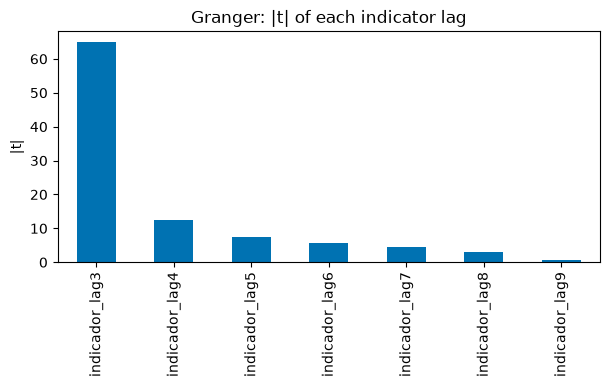

In [5]:
granger = report[report.method == "granger"].set_index("feature")
ax = granger["score"].plot.bar(figsize=(7, 3), color="#0072B2")
ax.set(title="Granger: |t| of each indicator lag", ylabel="|t|", xlabel="")
plt.show()

## 3. Controls and proposed models

The control is the same experiment without `X`. In the experiment with `X`, the `exogenous` family (bases with the covariates and residual corrections of the best of them) challenges the univariate champion after the residual structures; it enters only if it passes the acceptance rule.

In [6]:
plain_result = plain.compare_models()
exog_result = with_exog.compare_models()
pd.DataFrame(
    {"champion": [plain_result.best.label, exog_result.best.label]},
    index=["without covariates", "with covariates"],
)

,champion
without covariates,naive
with covariates,"linear(lags=7) | exog: indicador_lag3, indicad..."


## 4. Fitting and evaluation

The selection decisions, with median gain and win rate; then the best with and the best without covariates on the same `V_select` units, with Wilcoxon and Diebold–Mariano.

In [7]:
exog_result.decisions[
    ["family", "challenger_label", "accepted", "median_gain", "win_rate", "reason_codes"]
]

,family,challenger_label,accepted,median_gain,win_rate,reason_codes
0,linear,linear(lags=7),False,-0.305697,0.428571,"(median_gain_below_threshold, win_rate_below_t..."
1,residual,"naive + linear [w=7, alpha=0.5, historical_oof...",False,0.079145,0.571429,"(win_rate_below_threshold,)"
2,exogenous,"linear(lags=7) | exog: indicador_lag3, indicad...",True,0.692053,0.857143,"(accepted,)"


In [8]:
comparison = with_exog.compare_exog()
display(comparison.summary.round(3))
comparison.tests().round(4)

,mean,std,median,n_valid,n_units,mean_rank
model,,,,,,
linear+exog,0.040,0.022,0.036,7,7,1.0
naive-linear,0.173,0.138,0.092,7,7,2.0


,model,reference,n_units,mean_difference,median_difference,wins,wilcoxon_p,dm_statistic,dm_p,wilcoxon_p_holm,dm_p_holm
0,linear+exog,naive-linear,7,0.1333,0.0486,7,0.0156,2.6258,0.0393,0.0156,0.0393


## 5. Results and plots

Each champion is refitted on the history before the test and read once on the sealed test.

In [9]:
final_plain = plain.finalize_model(plain_result.best)
final_exog = with_exog.finalize_model(exog_result.best)
test_plain = plain.evaluate_external(final_plain)
test_exog = with_exog.evaluate_external(final_exog)
pd.concat([test_plain.metrics, test_exog.metrics]).round(3)

,MASE,MAE,RMSE,sMAPE
model,,,,
naive,0.110,0.567,0.676,0.002
"linear(lags=7) | exog: indicador_lag3, indicador_lag4, indicador_lag5, indicador_lag6, indicador_lag7, indicador_lag8",0.029,0.151,0.170,0.001


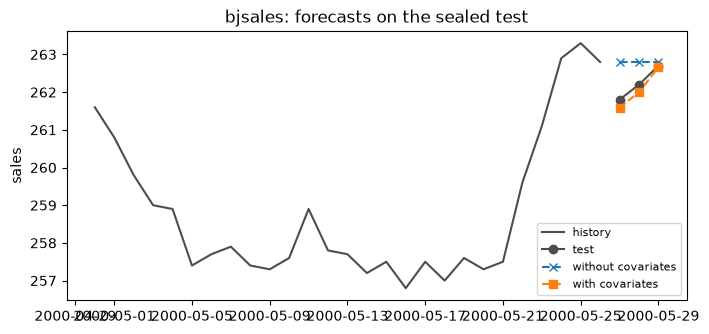

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
history = sales.iloc[-30:-3]
ax.plot(history.index, history.to_numpy(), color="0.3", label="history")
ax.plot(
    test_exog.predictions.index, test_exog.predictions["y_true"], "o-", color="0.3", label="test"
)
ax.plot(
    test_plain.predictions.index,
    test_plain.predictions["y_pred"],
    "x--",
    label="without covariates",
)
ax.plot(
    test_exog.predictions.index, test_exog.predictions["y_pred"], "s--", label="with covariates"
)
ax.set(title="bjsales: forecasts on the sealed test", ylabel="sales")
ax.legend(fontsize=8)
plt.show()

### Oracle: the day's own temperature

In `elecdaily`, the working day is calendar (`future`). The measured temperature is `past`: with a 7-day horizon it enters lagged by 7 days. Declaring it `future` uses the day's own temperature, which would only be known later: it is the error of someone with a perfect weather forecast, the ceiling of what such a forecast can bring.

In [11]:
def study(y, X, fh, future=(), selection=None):
    """Experiments without and with X; decision, tests and sealed-test MASE."""
    without = AutoHybridExperiment(fh=fh, **SETTINGS).fit(y)
    best_without = without.compare_models().best
    mase_without = (
        without.evaluate_external(without.finalize_model(best_without)).metrics["MASE"].iloc[0]
    )
    exp = AutoHybridExperiment(
        fh=fh, exog_future=list(future), exog_selection=selection, **SETTINGS
    ).fit(y, X)
    result = exp.compare_models()
    decision = result.decisions.set_index("family").loc["exogenous"]
    tests = exp.compare_exog().tests().iloc[0]
    mase_with = exp.evaluate_external(exp.finalize_model(result.best)).metrics["MASE"].iloc[0]
    return {
        "accepted": bool(decision.accepted),
        "median_gain": float(decision.median_gain),
        "win_rate": float(decision.win_rate),
        "wilcoxon_p": float(tests.wilcoxon_p),
        "dm_p": float(tests.dm_p),
        "test_mase_without": float(mase_without),
        "test_mase_with": float(mase_with),
    }


oracle = pd.DataFrame(
    {
        "past temperature": study(demand, weather, 7, future=["dia_util"]),
        "future temperature (oracle)": study(
            demand, weather, 7, future=["dia_util", "temperatura", "temperatura2"]
        ),
    }
).T.infer_objects()
oracle.round(3)

,accepted,median_gain,win_rate,wilcoxon_p,dm_p,test_mase_without,test_mase_with
past temperature,False,-0.040,0.429,0.578,0.388,1.954,1.954
future temperature (oracle),True,0.284,0.857,0.031,0.021,1.954,0.689


## 6. Diagnostics and limits

The same study on two more benchmarks, with automatic selection: `seatbelts` (monthly, horizon 12, seat belt law as `future`) and `uschange` (quarterly, horizon 8). `past` covariates must be lagged by the whole horizon; at long horizons they rarely inform, and the acceptance rule refuses them. The daily index of `bjsales` is synthetic.

In [12]:
bjsales_row = study(sales, indicator, 3, selection="auto")
y_seat, X_seat = load_exog_dataset("seatbelts")
y_us, X_us = load_exog_dataset("uschange")
benchmarks = pd.DataFrame(
    {
        "bjsales (fh=3)": bjsales_row,
        "elecdaily (fh=7)": oracle.iloc[0].to_dict(),
        "seatbelts (fh=12)": study(y_seat, X_seat, 12, future=["lei_cinto"], selection="auto"),
        "uschange (fh=8)": study(y_us, X_us, 8, selection="auto"),
    }
).T.infer_objects()
benchmarks.round(3)

,accepted,median_gain,win_rate,wilcoxon_p,dm_p,test_mase_without,test_mase_with
bjsales (fh=3),True,0.692,0.857,0.016,0.039,0.110,0.029
elecdaily (fh=7),False,-0.040,0.429,0.578,0.388,1.954,1.954
seatbelts (fh=12),False,-0.612,0.167,0.219,0.141,0.714,0.714
uschange (fh=8),False,-0.149,0.286,0.156,0.198,0.322,0.322


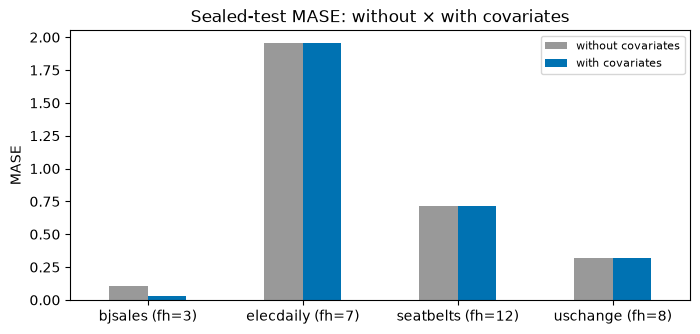

In [13]:
ax = benchmarks[["test_mase_without", "test_mase_with"]].plot.bar(
    figsize=(8, 3.5), rot=0, color=["0.6", "#0072B2"]
)
ax.set(title="Sealed-test MASE: without × with covariates", ylabel="MASE")
ax.legend(["without covariates", "with covariates"], fontsize=8)
plt.show()

## 7. Reading

- **Leading indicator (`bjsales`, horizon 3).** All six methods chose the indicator lagged 3 steps; `lasso` and `stepwise_bic` also took neighbouring lags. The `exogenous` family was accepted with a median gain of 69 % and 6 wins in 7 origins. Wilcoxon gave p = 0.016, the smallest possible with 7 units, and Diebold–Mariano p = 0.039. On the sealed test, MASE fell from 0.110 (persistence) to 0.029.
- **`past` temperature (`elecdaily`, horizon 7).** Lagged by 7 days, temperature did not help: a gain of −4 %, and the champion stayed univariate.
- **Oracle.** Declared `future`, the day's own temperature (and its square, since demand rises in cold and in heat) was accepted, with a gain of 28 %. Test MASE fell from 1.95 to 0.69. That is the ceiling: in production the column would come from a weather forecast, with error. The distance between 1.95 and 0.69 is what a good temperature forecast is worth for this series.
- **Long horizons.** In `seatbelts` (horizon 12) and `uschange` (horizon 8), `past` covariates lagged by the whole horizon made validation worse (gains of −61 % and −15 %). The acceptance rule refused them, and the final model is the same as without `X`.
- **Takeaway.** Covariates help when they lead the series by the horizon or are truly known in advance. When they do not, the selection refuses them and records why: the cost of offering them is only search time.